# Dense Knowledge Representation: CLIP vs. Qwen3-VL embeddings
**CAP6938 · Topic 1**  
Author: **Longho Bernard Che** · Date: **September 17, 2026**

Compare `openai/clip-vit-base-patch32` and `Qwen/Qwen3-VL-Embedding-2B`
on identical MMEB queries and candidate sets. This notebook covers image classification,
image retrieval, VQA, and grounding, then identifies failures for architectural analysis.

**Execution status:** This is an experiment notebook, not a completed submission.
Data loading, sampling, and decoding were checked on 96 real queries and 1,478 images.
The data-inspection outputs below are preserved; model results appear only after you run
the inference cells. The analysis cell then writes evidence-based drafts for the selected
failures. Review the images and the architectural interpretations before submitting.

### Run in Google Colab
1. Upload this `.ipynb` to [Colab](https://colab.research.google.com/).
2. Select **Runtime → Change runtime type → T4 GPU** (or another CUDA GPU).
3. Run the install cell, then the remaining cells in order. If Colab requests a restart,
   restart the session and continue from the imports cell. The configuration cell
   mounts Google Drive and saves all experiment data under
   `/content/drive/MyDrive/mmeb_analysis`.
4. Inspect the failure gallery and automatically generated `CASE_NOTES`. Revise any
   interpretation that the images do not support; record completed reviews in
   `REVIEWED_CASE_IDS`, then rerun the analysis and export cells.
5. Download the notebook **with outputs**, plus the exported results. Submit the
   separate **1–2-page PDF report** required by the spec.

The default is **24 queries × 4 datasets**, with **32 sampled candidates per query**.
Model weights require several GB of downloads. Models run sequentially; Qwen uses
batch size 1, FP16 on T4, and a bounded image resolution. Runtime depends on the GPU
and network. To try a smaller run, set `N_QUERIES = 4` first, then restore 24 or more.

## 1. Experimental design

| Category | MMEB subset | What is ranked? |
|---|---|---|
| IC | CIFAR-100 | Class labels for a query image |
| IR | CIRR | Images matching a reference image plus a requested change |
| VQA | TextVQA | Candidate text answers to an image question |
| Grounding | RefCOCO | Candidate object crops for an image and referring expression |

MMEB supplies the correct target **first** in every row. We retain it, deduplicate exact
text/path pairs, sample negatives without consulting either model, and shuffle candidates
with a recorded seed. Both models see the resulting identical inputs. No labels are passed
to either encoder. Set `MAX_CANDIDATES = None` to keep all unique supplied candidates.

The defaults measure **sampled-candidate top-1 accuracy and mean reciprocal rank (MRR)**,
not official benchmark scores. Retrieval here is within each row's supplied choices;
RefCOCO is crop retrieval, not bounding-box generation or IoU evaluation. Alternative
valid answers or duplicate image contents can still make a nominal failure ambiguous.

**CLIP mixed-input baseline:** Normalize its image and text embeddings separately, average
them with equal weight, and renormalize. CLIP does not jointly encode an image and question;
this explicit late-fusion adaptation is one part of the comparison. Qwen jointly encodes
the modalities within each input, using its official embedding wrapper. Query and candidate
are still encoded separately: Qwen is an embedder here, not a cross-encoder reranker.

Preserve MMEB's wording, removing only its `<|image_1|>` transport marker. Use each model's
native image processor. Differences in training, parameter count, resolution, prompts, and
the CLIP fusion rule are confounders. Case evidence and ablations can support an architectural
hypothesis, but do not isolate architecture as a causal variable.

In [ ]:
# Colab already supplies a compatible torch/torchvision pair; preserve that pair.
%pip -q install "transformers==4.57.6" "qwen-vl-utils==0.0.14" "accelerate>=1.12,<2" "datasets>=4.4,<5" "huggingface-hub>=0.34,<1" "fsspec[http]" pandas matplotlib pillow

In [1]:
import gc
import hashlib
import importlib.util
import importlib.metadata
import json
import platform
import re
import sys
import textwrap
import time
import zipfile
from pathlib import Path, PurePosixPath
from urllib.request import urlopen

import fsspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display, Markdown
from datasets import load_dataset
# All repositories used here are public. Explicit token=False on download/model calls
# avoids Colab Secrets lookups; an HF_TOKEN secret is not required.
from huggingface_hub import hf_hub_download, hf_hub_url, snapshot_download
from tqdm.auto import tqdm

def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()

def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(value, indent=2), encoding='utf-8')
    temporary.replace(path)

In [ ]:
SEED = 6938
N_QUERIES = 24
MAX_CANDIDATES = 32  # None = all unique original candidates; slower, especially for images.
N_FAILURE_CASES = 5
CLIP_BATCH_SIZE = 32
QWEN_BATCH_SIZE = 1
QWEN_MAX_PIXELS = 256 * 32 * 32  # At most ~256 visual tokens, subject to resizing rules.
QWEN_MAX_LENGTH = 2048

# Persist data, checkpoints, model downloads, and reports in the requested Drive folder.
WORK_DIR = Path('/content/drive/MyDrive/mmeb_analysis')
if not Path('/content/drive/MyDrive').is_dir():
    try:
        from google.colab import drive
    except ImportError as exc:
        raise RuntimeError('Open this notebook in Colab to use the configured Google Drive path.') from exc
    drive.mount('/content/drive')
WORK_DIR.mkdir(parents=True, exist_ok=True)
HUB_CACHE = WORK_DIR / 'hub_cache'
HUB_CACHE.mkdir(exist_ok=True)
DATASETS = {'IC': 'CIFAR-100', 'IR': 'CIRR', 'VQA': 'TextVQA', 'Grounding': 'RefCOCO'}
DATA_ID = 'TIGER-Lab/MMEB-eval'
DATA_REVISION = '2f069730be515ea60778413777816b53e2d2a697'
MODEL_IDS = {'clip': 'openai/clip-vit-base-patch32', 'qwen': 'Qwen/Qwen3-VL-Embedding-2B'}
MODEL_REVISIONS = {
    'clip': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268',
    'qwen': '9f2f7e710d6d81056aa5c0a4f04764fec6bb7bda',
}
QWEN_CODE_REVISION = '393e2978d27852b0d0230d6994f37f9c15bed73c'
PIPELINE_VERSION = '1.0'

assert N_QUERIES > 0
assert MAX_CANDIDATES is None or MAX_CANDIDATES >= 2
assert N_FAILURE_CASES >= 5
config = dict(seed=SEED, queries_per_dataset=N_QUERIES, max_candidates=MAX_CANDIDATES,
              datasets=DATASETS, data_revision=DATA_REVISION, model_ids=MODEL_IDS,
              model_revisions=MODEL_REVISIONS, qwen_code_revision=QWEN_CODE_REVISION,
              qwen_max_pixels=QWEN_MAX_PIXELS, qwen_max_length=QWEN_MAX_LENGTH,
              clip_fusion='normalized_equal_weight_mean', pipeline=PIPELINE_VERSION)
RUN_DIR = WORK_DIR / 'runs' / digest(config)[:12]
IMAGE_DIR = WORK_DIR / 'images' / DATA_REVISION[:12]
RUN_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
save_json(RUN_DIR / 'config.json', config)
print('Run directory:', RUN_DIR)
display(pd.DataFrame([{'category': c, 'dataset': d, 'queries': N_QUERIES,
                      'candidate_cap': MAX_CANDIDATES} for c, d in DATASETS.items()]))

## 2. Inspect and sample the actual MMEB rows

The small Parquet files contain `qry_text`, `qry_img_path`, `tgt_text`, and `tgt_img_path`.
Images are separate members of `images.zip` (about 7.1 GB). The next steps fetch only the
four selected metadata files, then use HTTP range reads to extract the required images.
The ZIP directory must also be read, so network traffic exceeds the saved image bytes.
There is no automatic full-archive fallback.

In [3]:
def clean_text(text):
    return re.sub(r'<\|image_\d+\|>', '', text or '').strip()

def make_item(text, image):
    item = {'text': clean_text(text), 'image': image or ''}
    if not item['text'] and not item['image']:
        raise ValueError('Encountered an empty MMEB input.')
    return item

def item_key(item):
    return (item['text'], item['image'])

def prepare_example(row, category, dataset, row_id):
    texts, images = row['tgt_text'], row['tgt_img_path']
    if len(texts) != len(images) or len(texts) < 2:
        raise ValueError(f'Invalid candidate lists: {dataset}:{row_id}')
    original = [make_item(t, i) for t, i in zip(texts, images)]
    # dict preserves order: the first unique item remains the annotated correct target.
    unique = list({item_key(x): x for x in original}.values())
    if len(unique) < 2:
        raise ValueError('Fewer than two distinct candidates.')
    rng = np.random.default_rng(int(digest([SEED, dataset, row_id])[:16], 16))
    count = len(unique) if MAX_CANDIDATES is None else min(MAX_CANDIDATES, len(unique))
    negatives = rng.choice(np.arange(1, len(unique)), size=count - 1, replace=False)
    selected = [unique[0]] + [unique[int(i)] for i in negatives]
    order = rng.permutation(count)
    candidates = [selected[int(i)] for i in order]
    gold = int(np.flatnonzero(order == 0)[0])
    assert item_key(candidates[gold]) == item_key(original[0])
    return dict(id=f'{dataset}:{row_id}', category=category, dataset=dataset, row_id=row_id,
                query=make_item(row['qry_text'], row['qry_img_path']), candidates=candidates,
                gold=gold, original_candidates=len(original), unique_candidates=len(unique))

examples, inspection = [], []
for category, dataset in DATASETS.items():
    metadata_path = hf_hub_download(DATA_ID, f'{dataset}/test-00000-of-00001.parquet',
                                    repo_type='dataset', revision=DATA_REVISION, cache_dir=HUB_CACHE, token=False)
    table = load_dataset('parquet', data_files=metadata_path, split='train',
                         cache_dir=str(WORK_DIR / 'datasets_cache'), token=False)
    required = {'qry_text', 'qry_img_path', 'tgt_text', 'tgt_img_path'}
    assert required.issubset(table.column_names), table.column_names
    if N_QUERIES > len(table):
        raise ValueError(f'{dataset} has only {len(table)} rows.')
    rng = np.random.default_rng(int(digest([SEED, dataset])[:16], 16))
    row_ids = sorted(rng.choice(len(table), N_QUERIES, replace=False).tolist())
    for row_id in row_ids:
        examples.append(prepare_example(table[row_id], category, dataset, row_id))
    first = table[row_ids[0]]
    inspection.append(dict(category=category, dataset=dataset, available_rows=len(table),
                           sampled_rows=len(row_ids), first_query=clean_text(first['qry_text']),
                           first_image=first['qry_img_path'],
                           original_candidates=len(first['tgt_text'])))

assert len({e['id'] for e in examples}) == len(examples)
save_json(RUN_DIR / 'sample_manifest.json', examples)
example_by_id = {e['id']: e for e in examples}
display(pd.DataFrame(inspection))
print('Sample manifest saved; every row includes the shuffled candidate list and gold index.')

CIFAR-100/test-00000-of-00001.parquet:   0%|          | 0.00/20.5k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

CIRR/test-00000-of-00001.parquet:   0%|          | 0.00/1.57M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

TextVQA/test-00000-of-00001.parquet:   0%|          | 0.00/1.57M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

RefCOCO/test-00000-of-00001.parquet:   0%|          | 0.00/1.86M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

,category,dataset,available_rows,sampled_rows,first_query,first_image,original_candidates
0,IC,CIFAR-100,1000,24,Represent the given image for classification,CIFAR-100/image_65.jpg,100
1,IR,CIRR,1000,24,"Given an image, find a similar everyday image ...",CIRR/dev-1032-3-img1.jpg,1000
2,VQA,TextVQA,1000,24,Represent the given image with the following q...,TextVQA/image_33.jpg,1000
3,Grounding,RefCOCO,1000,24,Select the portion of the image that follows t...,RefCOCO/image_1059389.jpg,1000


Sample manifest saved; every row includes the shuffled candidate list and gold index.


In [4]:
def local_image_path(relative):
    parts = PurePosixPath(relative)
    if parts.is_absolute() or '..' in parts.parts or '\\' in relative:
        raise ValueError(f'Unsafe image path: {relative}')
    return IMAGE_DIR.joinpath(*parts.parts)

def fetch_images(required_images):
    missing = [p for p in sorted(set(required_images)) if not local_image_path(p).is_file()]
    if not missing:
        print('All selected images are cached.')
        return
    url = hf_hub_url(DATA_ID, 'images.zip', repo_type='dataset', revision=DATA_REVISION)
    total_bytes = 0
    try:
        with fsspec.open(url, 'rb', block_size=262144, cache_type='blockcache',
                         cache_options={'maxblocks': 64}) as remote:
            with zipfile.ZipFile(remote) as archive:
                # Validate every name before downloading, and read in archive order.
                members = [(name, archive.getinfo(name)) for name in missing]
                members.sort(key=lambda pair: pair[1].header_offset)
                for name, info in tqdm(members, desc='Extract selected images'):
                    blob = archive.read(info)  # ZipFile validates member CRC.
                    path = local_image_path(name)
                    path.parent.mkdir(parents=True, exist_ok=True)
                    temporary = path.with_suffix(path.suffix + '.tmp')
                    temporary.write_bytes(blob)
                    temporary.replace(path)
                    total_bytes += len(blob)
    except Exception as exc:
        raise RuntimeError('Selective image download failed. Rerun to resume cached files. '
                           'If this network blocks HTTP Range, use a network that supports it, '
                           'or manually extract the official images.zip into IMAGE_DIR.') from exc
    print(f'Saved {len(missing)} images ({total_bytes / 1e6:.1f} MB of image content).')

def read_image(relative):
    with Image.open(local_image_path(relative)) as image:
        return image.convert('RGB')

required_images = {item['image'] for e in examples for item in [e['query'], *e['candidates']]
                   if item['image']}
fetch_images(required_images)
for relative in tqdm(sorted(required_images), desc='Validate image decoding'):
    image = read_image(relative)
    assert image.width > 0 and image.height > 0
print(f'{len(examples)} queries; {len(required_images)} unique images verified.')

Extract selected images:   0%|          | 0/1478 [00:00<?, ?it/s]

Saved 1478 images (24.1 MB of image content).


Validate image decoding:   0%|          | 0/1478 [00:00<?, ?it/s]

96 queries; 1478 unique images verified.


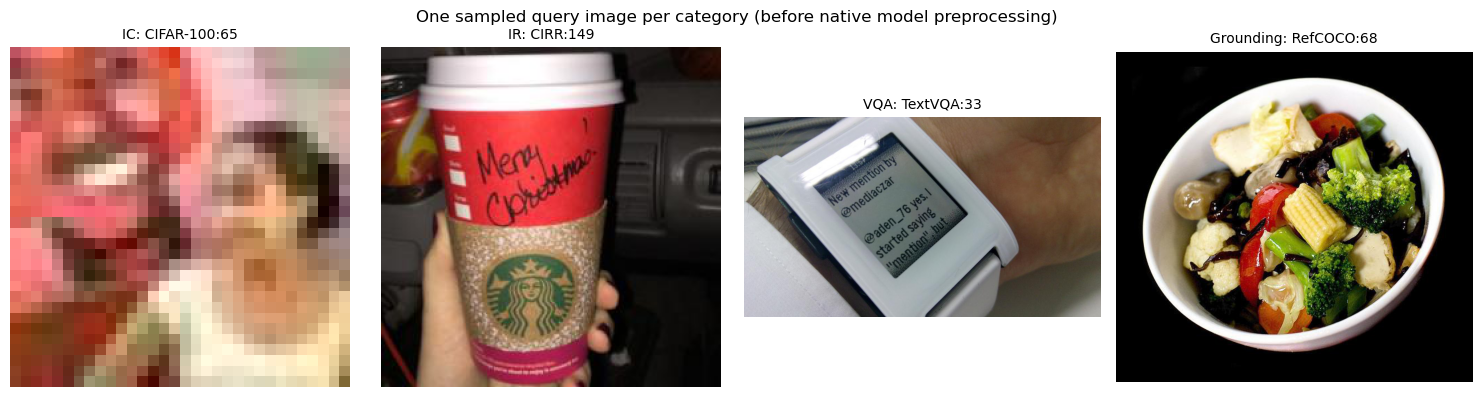

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, category in zip(axes, DATASETS):
    e = next(e for e in examples if e['category'] == category)
    if e['query']['image']:
        ax.imshow(read_image(e['query']['image']))
    ax.set_title(f"{category}: {e['id']}", fontsize=10)
    ax.axis('off')
fig.suptitle('One sampled query image per category (before native model preprocessing)')
plt.tight_layout()
plt.show()

## 3. Define the two embedding adapters

CLIP uses its projected, normalized features and native 77-token text limit. Truncated
inputs are reported and exported, so truncation can be considered in the case analysis.
Qwen uses the official wrapper at a fixed Git commit and a fixed model snapshot. Its last
non-padding token is pooled and normalized. We override preprocessing to **raise on invalid
images or excessive length**, rather than silently replacing an input or truncating it.

Image-only and text-only ablations remove the corresponding query modality, leaving
candidates unchanged. They are diagnostics; they are not additional trained models.
Removing query text also removes any task instruction contained in that text.

In [ ]:
import torch
import torch.nn.functional as F
from transformers import CLIPModel, CLIPProcessor

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(SEED)
if DEVICE == 'cuda':
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('No CUDA GPU detected. Data preparation works; choose a Colab GPU before inference.')
versions = {name: importlib.metadata.version(name) for name in
            ['torch', 'torchvision', 'transformers', 'qwen-vl-utils', 'datasets',
             'huggingface-hub', 'numpy', 'pandas', 'fsspec']}
environment = dict(python=sys.version, platform=platform.platform(), device=DEVICE,
                   gpu=torch.cuda.get_device_name(0) if DEVICE == 'cuda' else None,
                   versions=versions)
save_json(RUN_DIR / 'environment.json', environment)
display(pd.Series(versions, name='version').to_frame())

In [ ]:
class ClipEmbedder:
    def __init__(self):
        self.model = CLIPModel.from_pretrained(MODEL_IDS['clip'], revision=MODEL_REVISIONS['clip'], cache_dir=HUB_CACHE, token=False).to(DEVICE).eval()
        self.processor = CLIPProcessor.from_pretrained(MODEL_IDS['clip'], revision=MODEL_REVISIONS['clip'], cache_dir=HUB_CACHE, token=False)
        self.text_cache, self.image_cache = {}, {}
        self.truncated_texts = set()

    @torch.inference_mode()
    def encode(self, items):
        texts = list(dict.fromkeys(x['text'] for x in items if x['text'] and x['text'] not in self.text_cache))
        images = list(dict.fromkeys(x['image'] for x in items if x['image'] and x['image'] not in self.image_cache))
        limit = self.model.config.text_config.max_position_embeddings
        for start in range(0, len(texts), CLIP_BATCH_SIZE):
            batch = texts[start:start + CLIP_BATCH_SIZE]
            lengths = self.processor.tokenizer(batch, truncation=False, add_special_tokens=True)['input_ids']
            self.truncated_texts.update(t for t, tokens in zip(batch, lengths) if len(tokens) > limit)
            tokens = self.processor.tokenizer(batch, padding=True, truncation=True,
                                               max_length=limit, return_tensors='pt').to(DEVICE)
            values = F.normalize(self.model.get_text_features(**tokens).float(), dim=-1).cpu().numpy()
            self.text_cache.update(zip(batch, values))
        for start in range(0, len(images), CLIP_BATCH_SIZE):
            batch = images[start:start + CLIP_BATCH_SIZE]
            pixels = self.processor(images=[read_image(p) for p in batch], return_tensors='pt').to(DEVICE)
            values = F.normalize(self.model.get_image_features(**pixels).float(), dim=-1).cpu().numpy()
            self.image_cache.update(zip(batch, values))
        output = []
        for item in items:
            parts = []
            if item['text']:
                parts.append(self.text_cache[item['text']])
            if item['image']:
                parts.append(self.image_cache[item['image']])
            vector = np.mean(parts, axis=0)
            norm = np.linalg.norm(vector)
            if norm < 1e-10:
                raise ValueError('Degenerate CLIP fused vector.')
            output.append(vector / norm)
        return np.stack(output).astype(np.float32)

In [ ]:
# Fetch only the official helper source, pinned to a reviewed commit (no repository install).
source_url = (f'https://raw.githubusercontent.com/QwenLM/Qwen3-VL-Embedding/'
              f'{QWEN_CODE_REVISION}/src/models/qwen3_vl_embedding.py')
helper_path = WORK_DIR / 'vendor' / QWEN_CODE_REVISION / 'qwen3_vl_embedding.py'
helper_path.parent.mkdir(parents=True, exist_ok=True)
if not helper_path.exists():
    with urlopen(source_url, timeout=60) as response:
        helper_path.write_bytes(response.read())
spec = importlib.util.spec_from_file_location('cap6938_qwen_helper', helper_path)
qwen_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = qwen_module
spec.loader.exec_module(qwen_module)

class StrictQwenEmbedder(qwen_module.Qwen3VLEmbedder):
    def _preprocess_inputs(self, conversations):
        text = self.processor.apply_chat_template(conversations, add_generation_prompt=True, tokenize=False)
        images, videos, video_kwargs = qwen_module.process_vision_info(
            conversations, image_patch_size=16, return_video_metadata=True, return_video_kwargs=True)
        assert videos is None, 'This experiment handles image/text inputs only.'
        inputs = self.processor(text=text, images=images, truncation=False, padding=True,
                                do_resize=False, return_tensors='pt', **video_kwargs)
        if inputs['input_ids'].shape[1] > self.max_length:
            raise ValueError('Qwen input exceeds QWEN_MAX_LENGTH. Increase the limit or lower '
                             'QWEN_MAX_PIXELS, then rerun from configuration.')
        return inputs

class QwenEmbedder:
    def __init__(self):
        # A local snapshot pins both the processor and model; the upstream wrapper otherwise
        # forwards a revision only to model loading, not processor loading.
        path = snapshot_download(MODEL_IDS['qwen'], revision=MODEL_REVISIONS['qwen'], cache_dir=HUB_CACHE, token=False,
                                 allow_patterns=['*.json', '*.safetensors', '*.txt', '*.model', '*.jinja'])
        dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
        self.engine = StrictQwenEmbedder(model_name_or_path=path, torch_dtype=dtype,
                                         attn_implementation='sdpa', max_length=QWEN_MAX_LENGTH,
                                         max_pixels=QWEN_MAX_PIXELS, token=False)
        self.engine.model.config.use_cache = False
        self.engine.model.config.text_config.use_cache = False

    @torch.inference_mode()
    def encode(self, items):
        outputs = []
        for start in range(0, len(items), QWEN_BATCH_SIZE):
            batch = []
            for item in items[start:start + QWEN_BATCH_SIZE]:
                record = {}
                if item['text']:
                    record['text'] = item['text']
                if item['image']:
                    record['image'] = read_image(item['image'])
                batch.append(record)
            vectors = self.engine.process(batch)
            outputs.append(F.normalize(vectors.float(), dim=-1).cpu().numpy())
        return np.concatenate(outputs)

print('Official Qwen helper loaded from:', source_url)

## 4. Encode a shared corpus and evaluate

Identical inputs are encoded once per model. Embeddings are saved in small chunks with
configuration, model-revision, software-version, and corpus fingerprints; interrupted
inference can resume. To change the experiment, edit configuration and rerun from there.
Use the same native preprocessing in all query ablations. Never compare raw cosine scores
across models as calibrated confidence; compare rankings and within-model score margins.

In [6]:
corpus, corpus_index = [], {}
def register(item):
    key = item_key(item)
    if key not in corpus_index:
        corpus_index[key] = len(corpus)
        corpus.append(item)
    return corpus_index[key]

for e in examples:
    register(e['query'])
    for item in e['candidates']:
        register(item)
    if e['query']['text'] and e['query']['image']:
        register({'text': '', 'image': e['query']['image']})
        register({'text': e['query']['text'], 'image': ''})
print(f'{len(corpus)} distinct inputs including query ablations.')
corpus_hash = digest(corpus)
save_json(RUN_DIR / 'corpus.json', corpus)

def encode_cached(name, factory):
    fingerprint = digest({'config': config, 'corpus': corpus_hash, 'versions': versions,
                          'environment': environment, 'model': name})[:16]
    cache = RUN_DIR / f'{name}_embeddings_{fingerprint}'
    cache.mkdir(exist_ok=True)
    chunks, encoder = [], None
    try:
        for start in tqdm(range(0, len(corpus), 32), desc=f'{name} embedding chunks'):
            batch = corpus[start:start + 32]
            path = cache / f'{start:06d}.npz'
            if path.exists():
                with np.load(path, allow_pickle=False) as saved:
                    values = saved['embeddings']
            else:
                if encoder is None:
                    encoder = factory()
                values = encoder.encode(batch)
                if name == 'clip':
                    previous = cache / 'truncated_texts.json'
                    old = json.loads(previous.read_text()) if previous.exists() else []
                    save_json(previous, sorted(set(old) | encoder.truncated_texts))
                with path.with_suffix('.tmp').open('wb') as stream:
                    np.savez_compressed(stream, embeddings=values)
                path.with_suffix('.tmp').replace(path)
            assert values.ndim == 2 and len(values) == len(batch)
            assert np.isfinite(values).all(), 'Non-finite model output.'
            assert np.allclose(np.linalg.norm(values, axis=1), 1, atol=2e-3)
            chunks.append(values)
        if name == 'clip':
            log_path = cache / 'truncated_texts.json'
            truncated = json.loads(log_path.read_text()) if log_path.exists() else []
            print(f'CLIP truncated {len(truncated)} unique text inputs. Details: {log_path}')
            save_json(RUN_DIR / 'clip_truncated_texts.json', truncated)
    finally:
        del encoder
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return np.concatenate(chunks)

def rank_scores(scores, gold):
    scores = np.asarray(scores, dtype=np.float64)
    if scores.ndim != 1 or not np.isfinite(scores).all():
        raise ValueError('Invalid similarity scores.')
    # Candidate order was randomly permuted; ties must not privilege original target 0.
    order = np.argsort(-scores, kind='stable')
    rank = int(np.flatnonzero(order == gold)[0]) + 1
    negative_best = float(np.max(np.delete(scores, gold)))
    return dict(pred=int(order[0]), rank=rank, correct=bool(order[0] == gold),
                reciprocal_rank=1.0 / rank, margin=float(scores[gold] - negative_best),
                top_ties=int(np.sum(scores == scores[order[0]])), scores=scores.tolist())

def evaluate(name, embeddings):
    records = []
    for e in examples:
        targets = embeddings[[corpus_index[item_key(x)] for x in e['candidates']]]
        queries = {'full': e['query']}
        if e['query']['text'] and e['query']['image']:
            queries['image_only'] = {'text': '', 'image': e['query']['image']}
            queries['text_only'] = {'text': e['query']['text'], 'image': ''}
        for variant, query in queries.items():
            scores = targets @ embeddings[corpus_index[item_key(query)]]
            records.append(dict(id=e['id'], category=e['category'], dataset=e['dataset'],
                                model=name, variant=variant, gold=e['gold'],
                                n_candidates=len(e['candidates']), **rank_scores(scores, e['gold'])))
    save_json(RUN_DIR / f'{name}_predictions.json', records)
    return records

2440 distinct inputs including query ablations.


In [ ]:
# This cell downloads weights and runs real inference. No synthetic scores are used.
if DEVICE != 'cuda':
    raise RuntimeError('Choose Runtime → Change runtime type → GPU in Colab, then rerun '
                       'from the runtime cell. This experiment defaults to CUDA inference.')
records = []
timings = {}
for name, factory in [('clip', ClipEmbedder), ('qwen', QwenEmbedder)]:
    started = time.perf_counter()
    embeddings = encode_cached(name, factory)
    records.extend(evaluate(name, embeddings))
    timings[name] = time.perf_counter() - started
    del embeddings
save_json(RUN_DIR / 'timings.json', timings)
results = pd.DataFrame(records)
results.drop(columns='scores').to_csv(RUN_DIR / 'predictions.csv', index=False)
print('Both models completed. Elapsed seconds (includes loading/cache/network):', timings)

In [ ]:
# Can be rerun after reconnecting, once configuration and data cells restore the manifest.
records = []
for name in MODEL_IDS:
    records.extend(json.loads((RUN_DIR / f'{name}_predictions.json').read_text()))
results = pd.DataFrame(records)
full = results[results.variant == 'full'].copy()
assert full.groupby('model').size().to_dict() == {name: len(examples) for name in MODEL_IDS}
summary = full.groupby(['category', 'dataset', 'model'], sort=False).agg(
    queries=('correct', 'size'), top1_accuracy=('correct', 'mean'),
    MRR=('reciprocal_rank', 'mean'), mean_candidates=('n_candidates', 'mean'),
    tied_top_scores=('top_ties', lambda x: int((x > 1).sum()))).reset_index()
summary.to_csv(RUN_DIR / 'metrics.csv', index=False)
display(summary.round(3))
print('Chance top-1 for these candidate counts:', round((1 / full.n_candidates).mean(), 4))

fig, ax = plt.subplots(figsize=(8, 4))
summary.pivot(index='category', columns='model', values='top1_accuracy').reindex(DATASETS).plot.bar(ax=ax)
ax.set(ylabel='Top-1 accuracy', xlabel='', ylim=(0, 1),
       title='Sampled MMEB queries and candidate pools — not leaderboard scores')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
fig.savefig(RUN_DIR / 'accuracy.png', dpi=160, bbox_inches='tight')
plt.show()

ablation_summary = results.groupby(['category', 'model', 'variant'], sort=False).agg(
    queries=('correct', 'size'), top1_accuracy=('correct', 'mean'), MRR=('reciprocal_rank', 'mean')).reset_index()
ablation_summary.to_csv(RUN_DIR / 'ablation_metrics.csv', index=False)
display(ablation_summary.round(3))

## 5. Find and inspect failure cases

A failure is a query where **at least one model ranks the annotated target below first**.
The selector first seeks category diversity, then different outcomes (CLIP-only failure,
Qwen-only failure, both fail), and finally fills remaining slots in stable query order.
This does not assume Qwen wins. The full failure list is exported so the selection is auditable.
If fewer than five exist, increase `N_QUERIES` or the candidate pool and rerun; do not invent cases.

Each figure shows the input, annotated correct target, and each prediction. The table includes
top candidates, correct-target ranks, score margins, and query-modality ablations. Review the
actual images and answer ambiguity before attributing any error to architecture.

In [ ]:
paired = full.pivot(index='id', columns='model', values='correct').reindex([e['id'] for e in examples])
paired['category'] = [example_by_id[i]['category'] for i in paired.index]
paired['outcome'] = ['both correct' if c and q else 'CLIP-only failure' if not c and q
                     else 'Qwen-only failure' if c and not q else 'both fail'
                     for c, q in zip(paired['clip'], paired['qwen'])]
failures = paired[paired.outcome != 'both correct'].copy()
failures.to_csv(RUN_DIR / 'failure_candidates.csv')
display(pd.crosstab(paired.category, paired.outcome))

selected = []
for category in DATASETS:
    choices = failures.index[failures.category == category].tolist()
    if choices:
        selected.append(choices[0])
for outcome in ['CLIP-only failure', 'Qwen-only failure', 'both fail']:
    if len(selected) >= N_FAILURE_CASES:
        break
    choices = [i for i in failures.index[failures.outcome == outcome] if i not in selected]
    if choices and not any(failures.loc[i, 'outcome'] == outcome for i in selected):
        selected.append(choices[0])
selected += [i for i in failures.index if i not in selected][:max(0, N_FAILURE_CASES - len(selected))]
SELECTED_CASE_IDS = selected[:N_FAILURE_CASES]  # You may replace with reviewed IDs from failure_candidates.csv.
save_json(RUN_DIR / 'selected_cases.json', SELECTED_CASE_IDS)
print(f'{len(failures)} failure queries; selected {len(SELECTED_CASE_IDS)} for analysis.')
if len(SELECTED_CASE_IDS) < 5:
    print('NOT SUBMISSION-READY: increase N_QUERIES or MAX_CANDIDATES to find at least five failures.')
display(failures.loc[SELECTED_CASE_IDS])

In [ ]:
def result_for(case_id, model, variant='full'):
    match = results[(results.id == case_id) & (results.model == model) & (results.variant == variant)]
    assert len(match) == 1
    return match.iloc[0]

def draw_item(ax, item, title):
    ax.axis('off')
    ax.set_title(title, fontsize=10)
    if item['image']:
        ax.imshow(read_image(item['image']))
    else:
        ax.text(.5, .55, textwrap.fill(item['text'], 30), transform=ax.transAxes,
                ha='center', va='center', fontsize=12)
    if item['text'] and item['image']:
        ax.text(.5, -.04, textwrap.fill(item['text'], 38), transform=ax.transAxes,
                ha='center', va='top', fontsize=9)

def show_case(case_id):
    e = example_by_id[case_id]
    clip, qwen = result_for(case_id, 'clip'), result_for(case_id, 'qwen')
    display(Markdown(f"### {case_id} · {e['category']} · {failures.loc[case_id, 'outcome']}"))
    print('Query:', e['query']['text'])
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    draw_item(axes[0], e['query'], 'Query')
    draw_item(axes[1], e['candidates'][e['gold']], f"Annotated target (index {e['gold']})")
    draw_item(axes[2], e['candidates'][int(clip.pred)], f'CLIP prediction (gold rank {clip["rank"]})')
    draw_item(axes[3], e['candidates'][int(qwen.pred)], f'Qwen prediction (gold rank {qwen["rank"]})')
    plt.tight_layout()
    figure_path = RUN_DIR / 'cases' / f"{case_id.replace(':', '_')}.png"
    figure_path.parent.mkdir(exist_ok=True)
    fig.savefig(figure_path, dpi=150, bbox_inches='tight')
    plt.show()
    indices = {e['gold']}
    for result in [clip, qwen]:
        indices.update(np.argsort(-np.asarray(result.scores), kind='stable')[:3].tolist())
    candidates = []
    for i in sorted(indices):
        item = e['candidates'][i]
        candidates.append(dict(index=i, gold=i == e['gold'], text=item['text'], image=item['image'],
                               clip_cosine=clip.scores[i], qwen_cosine=qwen.scores[i]))
    display(pd.DataFrame(candidates).round(4))
    display(results[results.id == case_id][['model', 'variant', 'correct', 'rank', 'margin', 'top_ties']].round(4))
    for i in sorted(indices):
        if e['candidates'][i]['image']:
            print(f"Candidate {i} image: {local_image_path(e['candidates'][i]['image'])}")

for case_id in SELECTED_CASE_IDS:
    show_case(case_id)

## 6. Evidence-based failure analysis

The following cell fills all six analysis fields for every selected failure using its
actual query, annotated target, both predictions, ranks, score margins, and modality
ablations. It runs only after real prediction records exist. No model findings are
inferred from the dataset labels alone.

Each draft separates **measured observations** from an **architectural hypothesis**.
The hypothesis is specific to the task: fine-grained recognition for CIFAR-100, image/edit
composition for CIRR, question-conditioned visual text extraction for TextVQA, and
language-conditioned region selection for RefCOCO. It also states plausible confounders
and proposes a controlled follow-up experiment. Proposed experiments are not reported
as executed results.

Numerical observations can be generated from the saved records. Whether a distractor is
visually plausible, the annotation is ambiguous, or a proposed mechanism explains the
pixels still requires inspecting the gallery. Accordingly, generated notes start with a
**draft** status. `REVIEWED_CASE_IDS` records reviews that have actually been completed;
it must not be populated automatically to make the submission check pass. Reviewed edits
are retained on rerun only when their underlying query and prediction evidence match.

Architecture references: [CLIP](https://arxiv.org/abs/2103.00020),
[Qwen3-VL-Embedding](https://arxiv.org/abs/2601.04720), and the
[official Qwen implementation](https://github.com/QwenLM/Qwen3-VL-Embedding/blob/393e2978d27852b0d0230d6994f37f9c15bed73c/src/models/qwen3_vl_embedding.py).

In [ ]:
FIELDS = ['observation', 'mechanism', 'ablation_evidence',
          'alternative_explanation', 'counterfactual', 'conclusion']
ANALYSIS_VERSION = 'measured-case-draft-v1'
# Empty means no human visual review has yet been recorded; it is an explicit state.
REVIEWED_CASE_IDS = set()

MECHANISMS = {
    'IC': (
        'This task maps an image to a class label. CLIP compares separately learned image '
        'and text representations; its full query here also averages in a generic task '
        'instruction. Qwen can combine that instruction with visual tokens before pooling. '
        'Consequently, a full-versus-image-only rank change can reflect the handling of '
        'the instruction or our late-fusion choice, rather than better object recognition. '
        'CIFAR-100 starts with low-resolution images, so upscaling cannot recover missing '
        'detail. The pixels and competing labels must be inspected before blaming patch '
        'resolution or fine-grained feature loss.'
    ),
    'IR': (
        'This query requires preserving aspects of a reference image while applying a '
        'language edit. Our CLIP baseline averages independently computed image and text '
        'vectors, so the image representation is not conditioned on which attribute the '
        'edit changes. Qwen can combine the edit with visual tokens inside a single input '
        'before pooling. A gain over the image-only query is consistent with use of the '
        'edit, but does not by itself establish successful attribute binding. Inspect '
        'whether the predicted image satisfies the requested change and preserves the '
        'relevant reference content.'
    ),
    'VQA': (
        'This is candidate-answer retrieval, not free-form answer generation. The query '
        'asks for information in an image. CLIP late fusion cannot condition its visual '
        'features on the particular question; Qwen can combine question tokens and '
        'visual tokens before producing an embedding. For a question requiring visible '
        'writing, this may help connect the relevant text region to an answer. The '
        'rank evidence alone does not prove OCR occurred: language priors, candidate '
        'wording, visual resolution, and instruction tuning can also change the ranks.'
    ),
    'Grounding': (
        'The query combines a scene with a referring expression and retrieves an object '
        'crop. CLIP late fusion has no token-level interaction between that expression '
        'and the scene representation; Qwen can combine them before pooling. Spatial '
        'or attribute binding is therefore a plausible differentiator when the expression '
        'requires it. However, candidate crops can come from other scenes and can omit '
        'the original spatial context. Object appearance may be sufficient to rank the '
        'annotated crop. This experiment does not measure box localization or IoU.'
    ),
}

COUNTERFACTUALS = {
    'IC': (
        'Proposed, not run: hold query images and candidate identities fixed and replace '
        'each bare class label with the same photo-description template for both models. '
        'If the gold rank improves, compatibility between label wording and training '
        'prompts is an alternative to a visual-architecture explanation.'
    ),
    'IR': (
        'Proposed, not run: keep the reference image and all candidates fixed, replacing '
        'only the query text with a generic request to retrieve a similar image. '
        'Compare the original gold rank with this no-edit version. A worse rank without '
        'the edit supports useful edit conditioning; a stable rank suggests that '
        'reference-image similarity or other cues suffice for this candidate pool.'
    ),
    'VQA': (
        'Proposed, not run: after visually locating the question-relevant writing, mask '
        'only that region and keep the question and candidate answers fixed. A worse '
        'gold rank would support dependence on that visual evidence. If no such region '
        'exists or the answer is unreadable even to a human, the OCR hypothesis needs '
        'revision before performing this intervention.'
    ),
    'Grounding': (
        'Proposed, not run: keep the scene and candidate crops fixed and replace only '
        'the referring-expression text with a generic request for an object crop. '
        'A worse rank for the original annotated crop supports dependence on the '
        'expression. The generic request has no unique correct target, so use the '
        'rank change as a diagnostic, not as a new accuracy measurement.'
    ),
}

def describe_item(item):
    parts = []
    if item['text']:
        parts.append('text ' + json.dumps(item['text'], ensure_ascii=False))
    if item['image']:
        parts.append('image `' + item['image'] + '`')
    return '; '.join(parts)

def case_evidence_signature(case_id):
    rows = results[results.id == case_id].sort_values(['model', 'variant'])
    return digest({'example': example_by_id[case_id],
                   'predictions': rows.to_dict(orient='records'),
                   'analysis_version': ANALYSIS_VERSION})

def build_case_analysis(case_id):
    e = example_by_id[case_id]
    clip = result_for(case_id, 'clip')
    qwen = result_for(case_id, 'qwen')
    if bool(clip.correct) and bool(qwen.correct):
        raise ValueError(f'{case_id} is not a failure case.')
    count = len(e['candidates'])
    observation = (
        f"Query: {describe_item(e['query'])}. The annotated target is candidate "
        f"{e['gold']}: {describe_item(e['candidates'][e['gold']])}. "
        f'This comparison uses {count} shuffled, sampled candidates. '
    )
    for label, record in [('CLIP', clip), ('Qwen', qwen)]:
        target = e['candidates'][int(record.pred)]
        outcome = 'correct' if bool(record.correct) else 'incorrect under the supplied annotation'
        observation += (
            f'{label} selects candidate {int(record.pred)} ({outcome}): '
            f'{describe_item(target)}. The annotated target ranks {int(record["rank"])}/{count}; '
            f'its cosine margin over the best negative is {float(record.margin):+.4f}. '
        )
        if int(record.top_ties) > 1:
            observation += (
                f'{label} has {int(record.top_ties)} tied top scores; the recorded '
                'prediction uses the fixed shuffled-order tie rule. '
            )

    ablation_sentences = []
    for name in MODEL_IDS:
        rows = results[(results.id == case_id) & (results.model == name)].set_index('variant')
        if not {'full', 'image_only', 'text_only'}.issubset(rows.index):
            ablation_sentences.append(f'{name}: both modalities are not present, so paired modality ablations are unavailable.')
            continue
        full_rank, image_rank, text_rank = [int(rows.loc[v, 'rank'])
                                           for v in ['full', 'image_only', 'text_only']]
        delta = image_rank - full_rank
        effect = (f'improves the gold rank by {delta}' if delta > 0 else
                  f'worsens the gold rank by {-delta}' if delta < 0 else
                  'leaves the gold rank unchanged')
        sentence = (
            f'{name}: full rank {full_rank}, image-only rank {image_rank}, '
            f'text-only rank {text_rank}. Adding query text to the image {effect}. '
        )
        if text_rank == 1:
            sentence += ('The target also ranks first without the query image; this case '
                         'does not establish that visual evidence was necessary for success. ')
        elif full_rank < text_rank:
            sentence += ('The full query outranks the text-only query on the target, '
                         'which is consistent with a useful image contribution. ')
        else:
            sentence += ('Adding the query image does not improve the target rank over '
                         'text alone here, limiting claims of useful visual grounding. ')
        ablation_sentences.append(sentence)
    ablation_sentences.append('These interventions change the input modalities, not the trained architecture; candidates remain fixed.')

    clip_rank, qwen_rank = int(clip['rank']), int(qwen['rank'])
    if qwen_rank < clip_rank:
        comparison = f'Qwen ranks the target {clip_rank - qwen_rank} positions higher than CLIP.'
    elif clip_rank < qwen_rank:
        comparison = f'CLIP ranks the target {qwen_rank - clip_rank} positions higher than Qwen.'
    else:
        comparison = f'Both models put the target at rank {clip_rank}; this case shows no gold-rank advantage.'
    if not bool(clip.correct) and not bool(qwen.correct):
        comparison += ' Both still fail top-1 retrieval.'
        if int(clip.pred) == int(qwen.pred):
            comparison += ' Both choose the same distractor, motivating an annotation and ambiguity check.'
    conclusion = (
        comparison + ' The ablation results above establish input sensitivity for this '
        'query and sampled pool. The architectural mechanism remains a hypothesis, '
        'because training data, scale, native preprocessing, prompts, and the chosen '
        'CLIP fusion rule are not controlled. Visual review has not been inferred '
        'from numerical ranks.'
    )
    alternative = (
        f"The original MMEB row has {e['original_candidates']} entries and "
        f"{e['unique_candidates']} unique text/path pairs; this run uses {count}. "
        'The sampled negatives may omit a difficult distractor. An unannotated but '
        'valid answer or visually equivalent crop could also explain an apparent error. '
        'The two models differ in training, capacity, prompts, and native image '
        'preprocessing; these are not isolated architectural controls. '
    )
    truncated_path = RUN_DIR / 'clip_truncated_texts.json'
    if truncated_path.exists():
        truncated = set(json.loads(truncated_path.read_text()))
        affected = [x['text'] for x in [e['query'], *e['candidates']] if x['text'] in truncated]
        alternative += (f'CLIP truncated {len(affected)} inputs used in this case.' if affected else
                        'The saved CLIP truncation log reports no truncated text inputs in this case.')
    else:
        alternative += 'No CLIP truncation log is available for this analysis.'
    return dict(observation=observation, mechanism=MECHANISMS[e['category']],
                ablation_evidence=' '.join(ablation_sentences),
                alternative_explanation=alternative, counterfactual=COUNTERFACTUALS[e['category']],
                conclusion=conclusion, _evidence_signature=case_evidence_signature(case_id),
                _origin=ANALYSIS_VERSION, _reviewed=False)

notes_path = RUN_DIR / 'analysis_notes.json'
previous_notes = json.loads(notes_path.read_text()) if notes_path.exists() else {}
CASE_NOTES = {}
for case_id in SELECTED_CASE_IDS:
    generated = build_case_analysis(case_id)
    previous = previous_notes.get(case_id, {})
    preserve = (previous.get('_evidence_signature') == generated['_evidence_signature']
                and previous.get('_origin') == ANALYSIS_VERSION
                and all(isinstance(previous.get(f), str) and previous[f].strip() for f in FIELDS))
    CASE_NOTES[case_id] = previous if preserve else generated
    if case_id in REVIEWED_CASE_IDS:
        CASE_NOTES[case_id]['_reviewed'] = True

save_json(notes_path, CASE_NOTES)
for case_id in SELECTED_CASE_IDS:
    state = 'review recorded' if CASE_NOTES[case_id]['_reviewed'] else 'evidence-based draft; visual review not recorded'
    display(Markdown(f'### {case_id} — {state}'))
    for field in FIELDS:
        display(Markdown(f"**{field.replace('_', ' ').title()}:** {CASE_NOTES[case_id][field]}"))

In [ ]:
def note_complete(note):
    return all(isinstance(note.get(field), str) and note[field].strip()
               and note.get('_origin') == ANALYSIS_VERSION for field in FIELDS)

complete = [i for i in SELECTED_CASE_IDS if note_complete(CASE_NOTES.get(i, {}))]
valid_failures = all(i in failures.index for i in SELECTED_CASE_IDS)
checklist = pd.DataFrame([
    ('All four categories evaluated by both models', set(full.category) == set(DATASETS)
     and all(set(full[full.model == m].category) == set(DATASETS) for m in MODEL_IDS)),
    ('At least five distinct failure cases selected', len(set(SELECTED_CASE_IDS)) >= 5 and valid_failures),
    ('At least five evidence-based case drafts generated', len(set(complete)) >= 5),
    ('At least five case analyses visually reviewed',
     sum(bool(CASE_NOTES[i].get('_reviewed')) for i in set(complete)) >= 5),
], columns=['check', 'passed'])
display(checklist)

lines = ['# Case analysis notes', '', 'Metrics: see metrics.csv; configuration: see config.json.', '']
for case_id in SELECTED_CASE_IDS:
    lines += [f'## {case_id}', '',
              'Review recorded: ' + str(bool(CASE_NOTES[case_id].get('_reviewed'))), '']
    for field in FIELDS:
        lines += [f"**{field.replace('_', ' ').title()}:** {CASE_NOTES[case_id][field]}", '']
(RUN_DIR / 'case_analysis.md').write_text('\n'.join(lines), encoding='utf-8')

# Export a compact results ZIP, excluding weights and embedding caches.
export_path = RUN_DIR.parent / f'{RUN_DIR.name}_results.zip'
with zipfile.ZipFile(export_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in RUN_DIR.rglob('*'):
        if path.is_file() and path.suffix in {'.csv', '.json', '.md', '.png'} and not any(
                '_embeddings_' in part for part in path.relative_to(RUN_DIR).parts):
            archive.write(path, arcname=str(path.relative_to(RUN_DIR)))
print('Results bundle:', export_path)
print('Remaining manual checks: review analysis quality; write the 1–2-page PDF; '
      'save/download this notebook with outputs visible.')
# Optional in Colab:
# from google.colab import files
# files.download(str(export_path))

## 7. Report outline and references

For the separate **1–2-page PDF**, use a short methods paragraph (datasets, sample sizes,
candidate sampling, models, fusion, preprocessing), a compact results table, and at least
five concise case explanations tied to the figures and ablation results. Finish with the
limits of the architectural interpretation. The notebook holds the detailed evidence.

Primary sources used to build this notebook:

1. [MMEB-eval dataset card and target-order convention](https://huggingface.co/datasets/TIGER-Lab/MMEB-eval).
2. [VLM2Vec / original MMEB paper](https://arxiv.org/abs/2410.05160).
3. [CLIP paper](https://arxiv.org/abs/2103.00020) and
   [ViT-B/32 model card](https://huggingface.co/openai/clip-vit-base-patch32).
4. [Qwen3-VL-Embedding-2B model card](https://huggingface.co/Qwen/Qwen3-VL-Embedding-2B)
   and [technical report](https://arxiv.org/abs/2601.04720).
5. [Pinned official Qwen embedding implementation](https://github.com/QwenLM/Qwen3-VL-Embedding/blob/393e2978d27852b0d0230d6994f37f9c15bed73c/src/models/qwen3_vl_embedding.py).

**Troubleshooting:** If CUDA runs out of memory, keep `QWEN_BATCH_SIZE = 1`, lower
`QWEN_MAX_PIXELS`, and rerun from configuration; this changes the protocol and run ID.
Reducing query count reduces runtime but usually not per-input GPU memory. If dependency
imports fail after installation, restart the Colab session before rerunning imports.
The configured Google Drive folder retains images, metadata, model weights, partial
embeddings, and analysis notes across runtime resets. Reuse it to resume interrupted runs.

**Colab HF_TOKEN warning:** The resources used here are public. Download and model-loading
calls explicitly pass `token=False` to bypass automatic authentication and Colab Secrets
lookups. If an older notebook copy shows a secret-vault timeout, it is an authentication
warning, not evidence that the public download failed. Use this updated notebook or add
`token=False` to its Hugging Face loading calls, then rerun the affected cells.
